# Background aerosol, sources and chemistry: LCC_FUT − CTRL_FUT

**Question.** Does the forest expansion change the aerosol and chemistry background of the FUT runs, and through which sources?

**Runs.** CTRL_FUT `NF2100ssp585norbc_tropstratchem_nudg_ctrl_f19_f19-20261028` and LCC_FUT `…_lcc_f19_f19-20261028` (new chain), **2001–2025** (first 12 months dropped as spin-up). Both are nudged to the same PD winds, so year *y* of one run is paired with year *y* of the other.

**What can differ.** The two runs share every prescribed input (emission files, seawater DMS, SST and sea ice, greenhouse gases; §1 shows the namelist diff). The land cover differs at 46–82°N (`PCT_NAT_PFT`), so differences come from:
- the land surface itself (albedo, evaporation, roughness → temperature, boundary layer, clouds);
- the **online sources** that depend on land: **MEGAN BVOC** and **dust**;
- everything downstream: oxidants, SOA, sulfate, droplets.

Sea salt and ocean DMS can change only through the 10-m wind (sea ice and SST are prescribed and identical). Lightning NOx can change through convection.

**Companion notebook:** `../background-aerosol-pd-fut/background_aerosol_pd_fut.ipynb` (CTRL_PD vs CTRL_FUT; what each compound does is explained there).

**Statistics.** Yearly means; paired t-test of the 25 yearly differences (`analysis/stats.py` method, copied here). Maps: Benjamini–Hochberg FDR (α = 0.10) over the cells north of 45°N; **hatching = not significant**. Regions: global, **46–82°N** (the forest-expansion band: the only latitudes where the land cover differs), **modified cells** (land cells whose PFTs changed, `diagnostics/lcc-modified-cells/modified_cells.nc`), Arctic >66.5°N.

In [1]:
import os
os.environ.setdefault('HDF5_USE_FILE_LOCKING', 'FALSE')  # before netCDF4/xarray import
import re, difflib
from pathlib import Path
from concurrent.futures import ProcessPoolExecutor
import numpy as np
import pandas as pd
import xarray as xr
import netCDF4
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import matplotlib.path as mpath
import cartopy.crs as ccrs
from scipy import stats as sps

CASEDIR = Path.home() / 'cases/BRL_FRST_XPSN'
CASES = {'CTRL': 'NF2100ssp585norbc_tropstratchem_nudg_ctrl_f19_f19-20261028',
         'LCC': 'NF2100ssp585norbc_tropstratchem_nudg_lcc_f19_f19-20261028'}
ALIAS = {'CTRL': 'CTRL_FUT', 'LCC': 'LCC_FUT'}
PROC = Path('../../data/processed-data/postprocessing')
PROC_YEARS = '2001-2025'
YEARS = list(range(2001, 2026))
DMS_DIR = Path('/cluster/shared/noresm/inputdata/noresm-only/atm/cam/camoslo')
MOD_FILE = Path('../lcc-modified-cells/modified_cells.nc')
OUT = Path('background_aerosol_lcc_ctrl_fut_outputs')
CACHE, FIG, TAB = OUT / 'cache', OUT / 'figures', OUT / 'tables'
for d in (CACHE, FIG, TAB):
    d.mkdir(parents=True, exist_ok=True)
REBUILD_CACHE = False
N_WORKERS = 8
R_EARTH = 6.371e6
DPM = np.array([31, 28, 31, 30, 31, 30, 31, 31, 30, 31, 30, 31])  # noleap
LAT_MAP = 45  # maps and FDR north of this latitude
ALPHA_FDR = 0.10
# project palette, in order; CTRL = navy, LCC = red
TEAL, NAVY, PLUM, RED, ORANGE, GOLD, GREY = '#5D9A92', '#2C3990', '#9A4A84', '#BC423E', '#DE7A3A', '#EBC45C', '#CCCCCC'
PCOL = {'CTRL': NAVY, 'LCC': RED}

def cell_area(lat, nlon):
    lat = np.asarray(lat, float)
    edges = np.clip(np.concatenate([[-90], 0.5 * (lat[1:] + lat[:-1]), [90]]), -90, 90)
    band = R_EARTH**2 * np.deg2rad(360 / nlon) * np.diff(np.sin(np.deg2rad(edges)))
    return np.repeat(band[:, None], nlon, axis=1)  # m2

with xr.open_dataset(PROC / f'CTRL_FUT_atm_METEO_{PROC_YEARS}.nc') as g:
    AREA = xr.DataArray(cell_area(g.lat, g.lon.size), dims=('lat', 'lon'), coords=dict(lat=g.lat.values, lon=g.lon.values))
with xr.open_dataset(MOD_FILE) as m:
    assert np.allclose(m.lat, AREA.lat) and np.allclose(m.lon, AREA.lon)
    MOD = (m.modified.astype(bool)).assign_coords(lat=AREA.lat, lon=AREA.lon).load()
LAT = AREA.lat.broadcast_like(AREA)
REGIONS = {'global': AREA, '46–82°N': AREA * ((LAT >= 46) & (LAT <= 82)), 'modified cells': AREA * MOD,
           'Arctic >66.5°N': AREA * (LAT > 66.5)}
print('modified cells:', int(MOD.sum()), f'({float((AREA * MOD).sum()) / 1e12:.2f} million km²), lat',
      float(LAT.where(MOD).min()), '–', float(LAT.where(MOD).max()))

# --- statistics (as src/boreal_forest_expansion/analysis/stats.py) ---
def pvalue(d, dim='year'):
    """Two-sided one-sample t-test of the paired yearly differences."""
    def _p(x):
        with np.errstate(invalid='ignore', divide='ignore'):
            return sps.ttest_1samp(x, 0.0, axis=-1, nan_policy='omit').pvalue
    return xr.apply_ufunc(_p, d, input_core_dims=[[dim]])

def fdr_mask(p, within, alpha=ALPHA_FDR):
    """Benjamini-Hochberg over the cells in `within`."""
    pv = p.values.copy()
    valid = np.isfinite(pv) & within.values.astype(bool)
    sig = np.zeros_like(pv, dtype=bool)
    flat = pv[valid]
    if flat.size:
        ranked = np.sort(flat)
        below = np.nonzero(ranked <= alpha * np.arange(1, flat.size + 1) / flat.size)[0]
        if below.size:
            sig[valid] = flat <= ranked[below.max()]
    return xr.DataArray(sig, coords=p.coords, dims=p.dims)

# --- polar maps, hatching = not significant (as plotting/forcing_maps.add_stippling style='lines') ---
def cyclic(da):
    return xr.concat([da, da.isel(lon=0).assign_coords(lon=360.)], 'lon')

def polar(ax):
    ax.set_extent([-180, 180, LAT_MAP, 90], ccrs.PlateCarree())
    th = np.linspace(0, 2 * np.pi, 200)
    ax.set_boundary(mpath.Path(np.c_[np.sin(th), np.cos(th)] * 0.5 + 0.5), transform=ax.transAxes)
    ax.coastlines(lw=0.4)

def hatch(ax, mask):
    da = cyclic(mask.astype(float))
    cs = ax.contourf(da.lon, da.lat, np.where(da > 0.5, 1.0, np.nan), levels=[0.5, 1.5], colors='none',
                     hatches=['/////'], transform=ccrs.PlateCarree(), zorder=4)
    cs.set_edgecolor('dimgrey'); cs.set_linewidth(0.0); cs.set_hatch_linewidth(0.3)

def outline_modified(ax):
    da = cyclic(MOD.astype(float))
    ax.contour(da.lon, da.lat, da, levels=[0.5], colors='k', linewidths=0.5, transform=ccrs.PlateCarree(), zorder=5)

def sym_levels(vmax, n=6):
    """Symmetric linear levels, n per side, step rounded to 1-2-2.5-5."""
    step = vmax / n
    e = 10 ** np.floor(np.log10(step))
    step = min(m * e for m in (1, 2, 2.5, 5, 10) if m * e >= step * 0.999)
    return np.arange(-n, n + 1) * step

def diff_maps(fields, fname, suptitle, ncols=4):
    """fields: list of (title, unit, ctrl_yearly, lcc_yearly, test_domain)."""
    nrows = int(np.ceil(len(fields) / ncols))
    fig, axs = plt.subplots(nrows, ncols, figsize=(4.4 * ncols, 4.9 * nrows), subplot_kw=dict(projection=ccrs.NorthPolarStereo()))
    axs = np.atleast_1d(axs).ravel()
    for ax, (title, unit, c, l, dom) in zip(axs, fields):
        d = l - c
        dm = d.mean('year')
        north = (LAT >= LAT_MAP)
        within = north & dom
        sig = fdr_mask(pvalue(d), within)
        vmax = float(np.nanpercentile(np.abs(dm.where(within)), 99)) or 1e-30
        lv = sym_levels(vmax)
        polar(ax)
        dm = dm.where(dom)  # blank outside the source domain (e.g. no dust, land on ocean maps)
        im = ax.pcolormesh(cyclic(dm).lon, dm.lat, cyclic(dm), cmap='RdBu_r', norm=mcolors.BoundaryNorm(lv, 256, extend='both'),
                           transform=ccrs.PlateCarree(), shading='nearest')
        hatch(ax, within & ~sig)
        outline_modified(ax)
        w = REGIONS['modified cells']
        ax.set_title(f'{title}\nmodified cells: {float((dm * w).sum() / w.sum()):+.3g} {unit}', fontsize=9)
        cb = fig.colorbar(im, ax=ax, orientation='horizontal', shrink=0.9, pad=0.04, ticks=lv[::2] if len(lv) > 9 else lv,
                          format=lambda x, _: f'{x:g}')
        cb.set_label(unit, fontsize=8); cb.ax.tick_params(labelsize=7, rotation=45)
    for ax in axs[len(fields):]:
        ax.set_visible(False)
    fig.suptitle(suptitle + f'\nLCC_FUT − CTRL_FUT, {YEARS[0]}–{YEARS[-1]}; hatched = not significant (paired t-test, FDR {ALPHA_FDR} north of {LAT_MAP}°N); black line = modified cells', y=1.0, fontsize=10)
    fig.tight_layout()
    fig.savefig(FIG / fname, dpi=200, bbox_inches='tight')
    plt.show()

def region_table(fields, fname):
    """fields: {name: (unit, ctrl_yearly, lcc_yearly, factor to the table unit, 'mean'|'sum')}."""
    rows = []
    for name, (unit, c, l, fac, how) in fields.items():
        for r, w in REGIONS.items():
            agg = (lambda x: (x * w).sum(('lat', 'lon'))) if how == 'sum' else (lambda x: (x * w).sum(('lat', 'lon')) / w.sum())
            yc, yl = agg(c).values * fac, agg(l).values * fac
            d = yl - yc
            rows.append(dict(variable=name, unit=unit, region=r, CTRL_FUT=yc.mean(), LCC_FUT=yl.mean(), **{
                'LCC − CTRL': d.mean(), 'change %': 100 * d.mean() / yc.mean() if yc.mean() else np.nan,
                '95 % CI ±': sps.t.ppf(0.975, len(d) - 1) * d.std(ddof=1) / np.sqrt(len(d)),
                'p': sps.ttest_1samp(d, 0.0).pvalue}))
    tab = pd.DataFrame(rows).set_index(['variable', 'unit', 'region'])
    tab.to_csv(TAB / fname)
    return tab

def show(tab, regions=('global', 'modified cells', '46–82°N')):
    with pd.option_context('display.float_format', '{:.3g}'.format, 'display.max_rows', 200, 'display.width', 200):
        for r in regions:
            print(r); display(tab.xs(r, level='region'))

modified cells: 1161 (29.13 million km²), lat 46.42105263157893 – 82.42105263157893


## 1. Inputs: what differs between the two runs

Resolved namelists (`CaseDocs/`) and the SST/sea-ice setting, with the case names replaced by `<CASE>`. Every line that differs is printed.

In [2]:
def norm_lines(case, fname):
    txt = (CASEDIR / case / 'CaseDocs' / fname).read_text()
    return [l.rstrip() for l in txt.replace(case, '<CASE>').splitlines()]

files = sorted({f.name for c in CASES.values() for f in (CASEDIR / c / 'CaseDocs').iterdir() if f.is_file()})
ndiff = {}
for fname in files:
    a, b = (norm_lines(CASES[k], fname) for k in ('CTRL', 'LCC'))
    dl = [l for l in difflib.unified_diff(a, b, 'CTRL_FUT', 'LCC_FUT', n=0, lineterm='') if l[:1] in '+-' and l[:3] not in ('+++', '---')]
    ndiff[fname] = len(dl)
    if dl:
        print(f'=== {fname}'); print('\n'.join(dl))
print('files compared:', len(files), '| files with differences:', [f for f, n in ndiff.items() if n])
for key in ('SSTICE_DATA_FILENAME', 'RUN_REFCASE', 'RUN_REFDATE'):
    v = {k: re.search(rf'id="{key}" value="([^"]*)"', ''.join(f.read_text() for f in sorted((CASEDIR / c).glob('env_*.xml')))).group(1)
         for k, c in CASES.items()}
    print(f'{key}: ' + ('same: ' + v['CTRL'] if v['CTRL'] == v['LCC'] else str(v)))

=== atm_in
- avgflag_pertape		= 'A','I'
+ avgflag_pertape		= 'A'
- fincl2		= 'SFISOP','SFMTERP','MEG_BCARY','MEG_C3H6','MEG_BIGENE','MEG_CH3CHO','MEG_CH2O','MEG_C2H4'
- mfilt		= 1,48
- nhtfrq		= 0,1
+ mfilt		= 1
+ nhtfrq		= 0
- ncdata		= 'NF2100ssp585norbc_tropstratchem_spinup_ctrl_f19_f19-20261025.cam.i.0021-01-01-00000.nc'
+ ncdata		= 'NF2100ssp585norbc_tropstratchem_spinup_lcc_f19_f19-20261025.cam.i.0021-01-01-00000.nc'
=== atm_modelio.nml
-  logfile = "atm.log.1791916.261106-174543"
+  logfile = "atm.log.1791684.261106-150011"
=== cpl_modelio.nml
-  logfile = "cpl.log.1791916.261106-174543"
+  logfile = "cpl.log.1791684.261106-150011"
=== esp_modelio.nml
-  logfile = "esp.log.1791916.261106-174543"
+  logfile = "esp.log.1791684.261106-150011"
=== glc_modelio.nml
-  logfile = "glc.log.1791916.261106-174543"
+  logfile = "glc.log.1791684.261106-150011"
=== ice_in
-  ice_ic = "NF2100ssp585norbc_tropstratchem_spinup_ctrl_f19_f19-20261025.cice.r.0021-01-01-00000.nc"
+  ice_ic = "NF2100s

In [3]:
import gzip
ARCHIVES = [Path('/cluster/work/users/adelez/archive'), Path.home() / 'BRL-FRST-XPSN_archive']  # live archive first (has 2015–2025)
SEC_YR = 365 * 86400
MW_DMS, MW_S = 62.13, 32.06
# Salter et al. (2015) sea-salt number flux, 3 modes: coefficients of SST³, SST², SST, 1 (oslo_aero_seasalt.F90)
SS_COEF = np.array([[-5.2168e5, 3.31725e7, -6.95275e8, 1.0684e10],
                    [0.0,       7.374e5,  -2.4803e7,   7.7373e8],
                    [0.0,       1.4210e4,  1.4662e7,   1.7075e8]])

def read_nml(case, key, fname='atm_in'):
    txt = (CASEDIR / case / 'CaseDocs' / fname).read_text()
    return re.search(rf"\b{key}\s*=\s*(.*?)\n\s*(?:\w+\s*=|/)", txt, re.S).group(1).strip()

def xml_value(case, key):
    for f in sorted((CASEDIR / case).glob('env_*.xml')):
        m = re.search(rf'id="{key}" value="([^"]*)"', f.read_text())
        if m:
            return m.group(1)
    raise KeyError(key)

def yearly(da, years):
    """Monthly means -> calendar-year means weighted by days per month; dims (year, lat, lon)."""
    w = da.time.dt.days_in_month
    out = (da * w).groupby('time.year').sum('time') / w.groupby('time.year').sum('time')
    assert set(years) <= set(out.year.values.tolist()), (years, out.year.values)
    return out.sel(year=list(years))

def hist_files(case, comp, years):
    """Raw monthly h0 files of `years`, from the first archive that has all of them."""
    tag = 'clm2' if comp == 'lnd' else 'cam'
    for root in ARCHIVES:
        fs = [root / case / comp / 'hist' / f'{case}.{tag}.h0.{y}-{m:02d}.nc' for y in years for m in range(1, 13)]
        if all(f.is_file() for f in fs):
            return fs
    raise FileNotFoundError(f'{case} {comp} h0 {years[0]}–{years[-1]}')

# --- MEGAN: CAM species <- CLM compounds (megan_specifier in drv_flds_in) ---
def megan_groups(case):
    spec = re.findall(r"'([^']*)'", read_nml(case, 'megan_specifier', 'drv_flds_in'))
    return {k.strip(): [c.strip() for c in v.split('+')] for k, v in (s.split('=') for s in spec)}

def megan_yearly(alias, case, years):
    """kg m-2 s-1 per grid-cell area: sum of the CLM compounds of each CAM species x landfrac."""
    with xr.open_dataset(PROC / f'{alias}_lnd_BVOC_{PROC_YEARS}.nc') as ds:
        assert ds.attrs['casename'] == case, (alias, ds.attrs['casename'])
        lf = ds.landfrac.fillna(0)
        lf = lf.isel(time=0) if 'time' in lf.dims else lf
        out = {sp: yearly(sum(ds[f'MEG_{c}'].fillna(0) for c in comps) * lf, years)
               for sp, comps in megan_groups(case).items()}
    return xr.Dataset(out).assign_coords(lat=AREA.lat, lon=AREA.lon).load()

# --- dust: CLM DSTFLXT x landfrac x erodibility / dust_emis_fact x 1.15 (oslo_aero_dust_emis) ---
def _dust_month(args):
    path, fac = args
    with netCDF4.Dataset(path) as d:
        return np.ma.filled(d['DSTFLXT'][0], 0.) * np.ma.filled(d['landfrac'][:], 0.) * fac

def dust_yearly(alias, case, years):
    f = CACHE / f'dust_{alias}_{years[0]}-{years[-1]}.nc'
    if f.is_file() and not REBUILD_CACHE:
        return xr.open_dataarray(f).load()
    erod = xr.open_dataset(read_nml(case, 'soil_erod_file').strip("'")).mbl_bsn_fct_geo
    assert erod.shape == AREA.shape and np.allclose(erod.lat[1:-1], AREA.lat[1:-1])  # same grid (file poles at ±89.5)
    fac = np.where(erod.values < 0.1, 0., erod.values) / float(read_nml(case, 'dust_emis_fact').replace('D0', '')) * 1.15
    files = hist_files(case, 'lnd', years)
    with ProcessPoolExecutor(N_WORKERS) as ex:
        mon = np.stack(list(ex.map(_dust_month, [(p, fac) for p in files]))).reshape(len(years), 12, *AREA.shape)
    da = xr.DataArray((mon * DPM[None, :, None, None]).sum(1) / DPM.sum(), dims=('year', 'lat', 'lon'),
                      coords=dict(year=list(years), lat=AREA.lat, lon=AREA.lon), name='dust',
                      attrs=dict(units='kg m-2 s-1', case=case))
    da.to_netcdf(f)
    return da

# --- ocean: DMS flux and sea-salt number flux, offline from monthly means with the model formulas ---
def ocean_yearly(alias, case, years):
    """oslo_aero_ocean.F90 (DMS 'lana', HAMOCC transfer velocity) and oslo_aero_seasalt.F90 (Salter et al. 2015).
    Inputs: model U10, OCNFRAC, ICEFRAC (monthly), prescribed SST and seawater DMS (monthly climatologies)."""
    with xr.open_dataset(PROC / f'{alias}_atm_METEO_{PROC_YEARS}.nc') as ds:
        assert ds.attrs['casename'] == case, (alias, ds.attrs['casename'])
        m = ds[['U10', 'OCNFRAC', 'ICEFRAC']].load()
    with xr.open_dataset(xml_value(case, 'SSTICE_DATA_FILENAME'), decode_times=False) as s:
        sst = s.SST_cpl_prediddle.load()   # deg C
    with xr.open_dataset(DMS_DIR / read_nml(case, 'ocean_filename').strip("'"), decode_times=False) as s:
        dms = s.dms.fillna(0).load()       # nmol L-1
    for x in (sst, dms):
        assert x.sizes['time'] == 12 and np.allclose(x.lat, m.lat) and np.allclose(x.lon, m.lon)
    idx = m.time.dt.month.values - 1
    like = lambda x: xr.DataArray(x.values[idx], dims=m.U10.dims, coords=m.U10.coords)
    t, c, u = like(sst), like(dms), m.U10
    open_ = (m.OCNFRAC * (1 - m.ICEFRAC)).clip(0, 1)
    sc = 2855.7 + (-177.63 + (6.0438 + (-0.11645 + 0.00094743 * t) * t) * t) * t   # Schmidt number of DMS
    fdms = (MW_DMS * 6.97e-7 * open_ * u**2 * np.sqrt(660 / sc) * 1e-9 * c).fillna(0)  # kg DMS m-2 s-1
    wc = 2e-8 * u**3.74 * open_                                                        # whitecap fraction
    out = dict(DMS_flux=yearly(fdms, years), open_ocean=yearly(open_, years))
    for n, (a, b, cc, d) in enumerate(SS_COEF, 1):
        out[f'seasalt_n{n}'] = yearly((wc * (((a * t + b) * t + cc) * t + d)).fillna(0).clip(min=0), years)  # m-2 s-1
    return xr.Dataset(out).assign_coords(lat=AREA.lat, lon=AREA.lon).load()

# --- lightning NOx: CAM prints the global value every time step in atm.log ---
def lightning_yearly(case, years):
    f = CACHE / f'lightning_{case}.csv'
    if f.is_file() and not REBUILD_CACHE:
        s = pd.read_csv(f, index_col=0).iloc[:, 0]
    else:
        steps = int(xml_value(case, 'ATM_NCPL')) * 365
        logs = {}
        for root in ARCHIVES:
            for g in sorted((root / case / 'logs').glob('atm.log.*.gz')):
                logs.setdefault(g.name, g)
        out = {}
        for g in logs.values():
            y0, v = None, []
            with gzip.open(g, 'rt', errors='replace') as fh:
                for line in fh:
                    if 'lightning NOx (TgN/y)' in line:
                        v.append(float(line.rsplit('=', 1)[1].split()[1]))
                    elif y0 is None and 'Current date (yr mon day tod)' in line:
                        y0 = int(line.split(':')[1].split()[0])
            if len(v) % steps == 1:   # the first segment also prints step 0
                v = v[1:]
            assert len(v) % steps == 0, (g.name, len(v))
            for k in range(len(v) // steps):
                assert y0 + k not in out, (g.name, y0 + k)
                out[y0 + k] = float(np.mean(v[k * steps:(k + 1) * steps]))
        s = pd.Series(out, name='lightning NOx (Tg N/yr)').sort_index()
        s.to_csv(f)
    missing = set(years) - set(s.index)
    assert not missing, (case, sorted(missing))
    return s.loc[list(years)]

# --- greenhouse-gas lower boundary condition (flbc_file, cycle year) ---
def lbc_means(case, species=('CH4', 'N2O', 'CO2')):
    yr = int(read_nml(case, 'flbc_cycle_yr'))
    with xr.open_dataset(read_nml(case, 'flbc_file').strip("'"), decode_times=False) as ds:
        it = np.nonzero(ds.date.values // 10000 == yr)[0]
        assert len(it) == 12, (case, yr, len(it))
        w = np.cos(np.deg2rad(ds.lat))
        return yr, {sp: float((ds[f'{sp}_LBC'].isel(time=it).mean('time') * w).sum() / w.sum()) for sp in species}

## 2. Online sources: MEGAN BVOC, dust, sea salt, ocean DMS flux, lightning NOx

How each source is computed (same code as the PD/FUT notebook, §9 there):
- **MEGAN**: CLM `MEG_<compound>` × `landfrac`, summed into the 19 CAM species with `megan_specifier`; checked against CAM `MEG_ISOP`/`MEG_MTERP` (a).
- **Dust**: raw CLM `DSTFLXT` × `landfrac` × erodibility / `dust_emis_fact` × 1.15, as in `oslo_aero_dust_emis` (formula (a); the absolute value (b): no CAM dust-emission output to check).
- **Sea salt, DMS flux**: model formulas applied offline to **monthly means** of `U10`, `OCNFRAC`, `ICEFRAC` and the prescribed SST / seawater DMS (b). Sea ice, SST and seawater DMS are identical in the two runs, so only the 10-m wind can change these.
- **Lightning NOx**: the global value CAM prints every time step in `atm.log`, averaged per year (a).

In [4]:
SRC, LIGHT = {}, {}
for k in CASES:
    SRC[k] = xr.merge([megan_yearly(ALIAS[k], CASES[k], YEARS), ocean_yearly(ALIAS[k], CASES[k], YEARS),
                       dust_yearly(ALIAS[k], CASES[k], YEARS).rename('dust')])
    LIGHT[k] = lightning_yearly(CASES[k], YEARS)

for k in CASES:  # check: CLM compounds x landfrac = what CAM receives from MEGAN
    with xr.open_dataset(PROC / f'{ALIAS[k]}_atm_BVOC_{PROC_YEARS}.nc') as ds:
        assert ds.attrs['casename'] == CASES[k]
        for sp in ('ISOP', 'MTERP'):
            cam = yearly(ds[f'MEG_{sp}'], YEARS).assign_coords(lat=AREA.lat, lon=AREA.lon)
            r = float((SRC[k][sp] * AREA).sum() / (cam * AREA).sum())
            print(f'{ALIAS[k]} {sp}: CLM-based / CAM MEG_{sp} = {r:.5f}')
            assert abs(r - 1) < 1e-3

MEG_OTHER = [v for v in megan_groups(CASES['CTRL']) if v not in ('ISOP', 'MTERP', 'BCARY', 'CH3OH')]
T = 1e-9 * SEC_YR  # kg s-1 -> Tg yr-1
SRC_FIELDS = {
    'MEGAN isoprene': ('Tg yr⁻¹', lambda d: d.ISOP, T),
    'MEGAN monoterpenes': ('Tg yr⁻¹', lambda d: d.MTERP, T),
    'MEGAN sesquiterpenes': ('Tg yr⁻¹', lambda d: d.BCARY, T),
    'MEGAN methanol': ('Tg yr⁻¹', lambda d: d.CH3OH, T),
    'MEGAN other (15 species)': ('Tg yr⁻¹', lambda d: sum(d[v] for v in MEG_OTHER), T),
    'dust': ('Tg yr⁻¹', lambda d: d.dust, T),
    'DMS flux (offline)': ('Tg S yr⁻¹', lambda d: d.DMS_flux * MW_S / MW_DMS, T),
    'sea salt, mode 1 (offline)': ('10²⁷ yr⁻¹', lambda d: d.seasalt_n1, 1e-27 * SEC_YR),
    'sea salt, mode 2 (offline)': ('10²⁷ yr⁻¹', lambda d: d.seasalt_n2, 1e-27 * SEC_YR),
    'sea salt, mode 3 (offline)': ('10²⁷ yr⁻¹', lambda d: d.seasalt_n3, 1e-27 * SEC_YR),
}
SRC_TAB = region_table({n: (u, f(SRC['CTRL']), f(SRC['LCC']), fac, 'sum') for n, (u, f, fac) in SRC_FIELDS.items()},
                       f'online_sources_lcc_ctrl_fut_{YEARS[0]}-{YEARS[-1]}.csv')
dl = LIGHT['LCC'] - LIGHT['CTRL']
LIGHT_TAB = pd.DataFrame({'CTRL_FUT': [LIGHT['CTRL'].mean()], 'LCC_FUT': [LIGHT['LCC'].mean()], 'LCC − CTRL': [dl.mean()],
                          'change %': [100 * dl.mean() / LIGHT['CTRL'].mean()],
                          '95 % CI ±': [sps.t.ppf(0.975, len(dl) - 1) * dl.std(ddof=1) / np.sqrt(len(dl))],
                          'p': [sps.ttest_1samp(dl, 0.0).pvalue]}, index=['lightning NOx, global (Tg N yr⁻¹)'])
pd.DataFrame(LIGHT).rename(columns=ALIAS).rename_axis('year').to_csv(TAB / 'lightning_nox_yearly.csv')
show(SRC_TAB)
with pd.option_context('display.float_format', '{:.3g}'.format):
    display(LIGHT_TAB)

CTRL_FUT ISOP: CLM-based / CAM MEG_ISOP = 1.00000
CTRL_FUT MTERP: CLM-based / CAM MEG_MTERP = 0.99978
LCC_FUT ISOP: CLM-based / CAM MEG_ISOP = 1.00000
LCC_FUT MTERP: CLM-based / CAM MEG_MTERP = 0.99978
global


,,CTRL_FUT,LCC_FUT,LCC − CTRL,change %,95 % CI ±,p
variable,unit,,,,,,
MEGAN isoprene,Tg yr⁻¹,885,887,1.31,0.148,1.1,0.0219
MEGAN monoterpenes,Tg yr⁻¹,510,510,0.427,0.0837,0.482,0.0801
MEGAN sesquiterpenes,Tg yr⁻¹,56.9,56.9,-0.00508,-0.00892,0.0653,0.874
MEGAN methanol,Tg yr⁻¹,298,297,-0.74,-0.249,0.239,1.33e-06
MEGAN other (15 species),Tg yr⁻¹,721,720,-0.878,-0.122,0.648,0.01
dust,Tg yr⁻¹,4.03e+03,4.03e+03,1.02,0.0253,24.4,0.932
DMS flux (offline),Tg S yr⁻¹,15.7,15.7,0.000218,0.00139,0.00214,0.836
"sea salt, mode 1 (offline)",10²⁷ yr⁻¹,2.64,2.64,-0.000237,-0.00894,0.000355,0.182
"sea salt, mode 2 (offline)",10²⁷ yr⁻¹,0.255,0.255,-1.39e-05,-0.00546,3.89e-05,0.467


modified cells


,,CTRL_FUT,LCC_FUT,LCC − CTRL,change %,95 % CI ±,p
variable,unit,,,,,,
MEGAN isoprene,Tg yr⁻¹,12.5,12.9,0.346,2.76,0.0445,2.56e-14
MEGAN monoterpenes,Tg yr⁻¹,22.1,22,-0.139,-0.629,0.0572,3.87e-05
MEGAN sesquiterpenes,Tg yr⁻¹,2.08,2.02,-0.0597,-2.87,0.00816,9.36e-14
MEGAN methanol,Tg yr⁻¹,17.8,17,-0.863,-4.84,0.0489,1.57e-22
MEGAN other (15 species),Tg yr⁻¹,27.3,25.9,-1.4,-5.13,0.0751,4.44e-23
dust,Tg yr⁻¹,0.0132,0.0132,2.23e-05,0.169,0.00464,0.992
DMS flux (offline),Tg S yr⁻¹,0.0969,0.0971,0.000183,0.189,5e-05,8.72e-08
"sea salt, mode 1 (offline)",10²⁷ yr⁻¹,0.0138,0.0137,-7.37e-05,-0.535,8.68e-06,3.5e-15
"sea salt, mode 2 (offline)",10²⁷ yr⁻¹,0.00114,0.00113,-5.51e-06,-0.485,7e-07,1.89e-14


46–82°N


,,CTRL_FUT,LCC_FUT,LCC − CTRL,change %,95 % CI ±,p
variable,unit,,,,,,
MEGAN isoprene,Tg yr⁻¹,23.2,23.6,0.37,1.59,0.0583,2.05e-12
MEGAN monoterpenes,Tg yr⁻¹,34.7,34.6,-0.109,-0.313,0.0707,0.0041
MEGAN sesquiterpenes,Tg yr⁻¹,3.35,3.3,-0.0558,-1.66,0.00976,1.8e-11
MEGAN methanol,Tg yr⁻¹,32.9,32,-0.821,-2.5,0.064,2.85e-19
MEGAN other (15 species),Tg yr⁻¹,49.4,48.1,-1.34,-2.71,0.102,1.71e-19
dust,Tg yr⁻¹,136,136,-0.145,-0.107,0.436,0.498
DMS flux (offline),Tg S yr⁻¹,0.999,0.998,-0.000364,-0.0365,0.000228,0.00306
"sea salt, mode 1 (offline)",10²⁷ yr⁻¹,0.226,0.225,-0.000246,-0.109,3.35e-05,8.65e-14
"sea salt, mode 2 (offline)",10²⁷ yr⁻¹,0.0198,0.0197,-1.98e-05,-0.1,2.96e-06,6.68e-13


,CTRL_FUT,LCC_FUT,LCC − CTRL,change %,95 % CI ±,p
"lightning NOx, global (Tg N yr⁻¹)",4.9,4.91,0.00723,0.148,0.0138,0.29


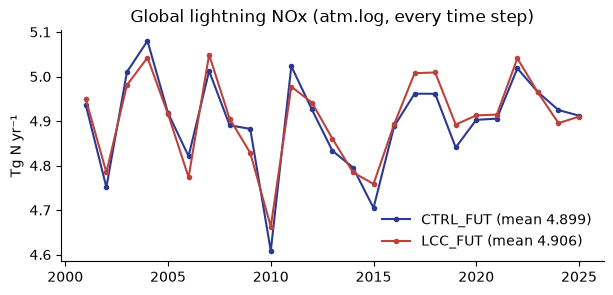

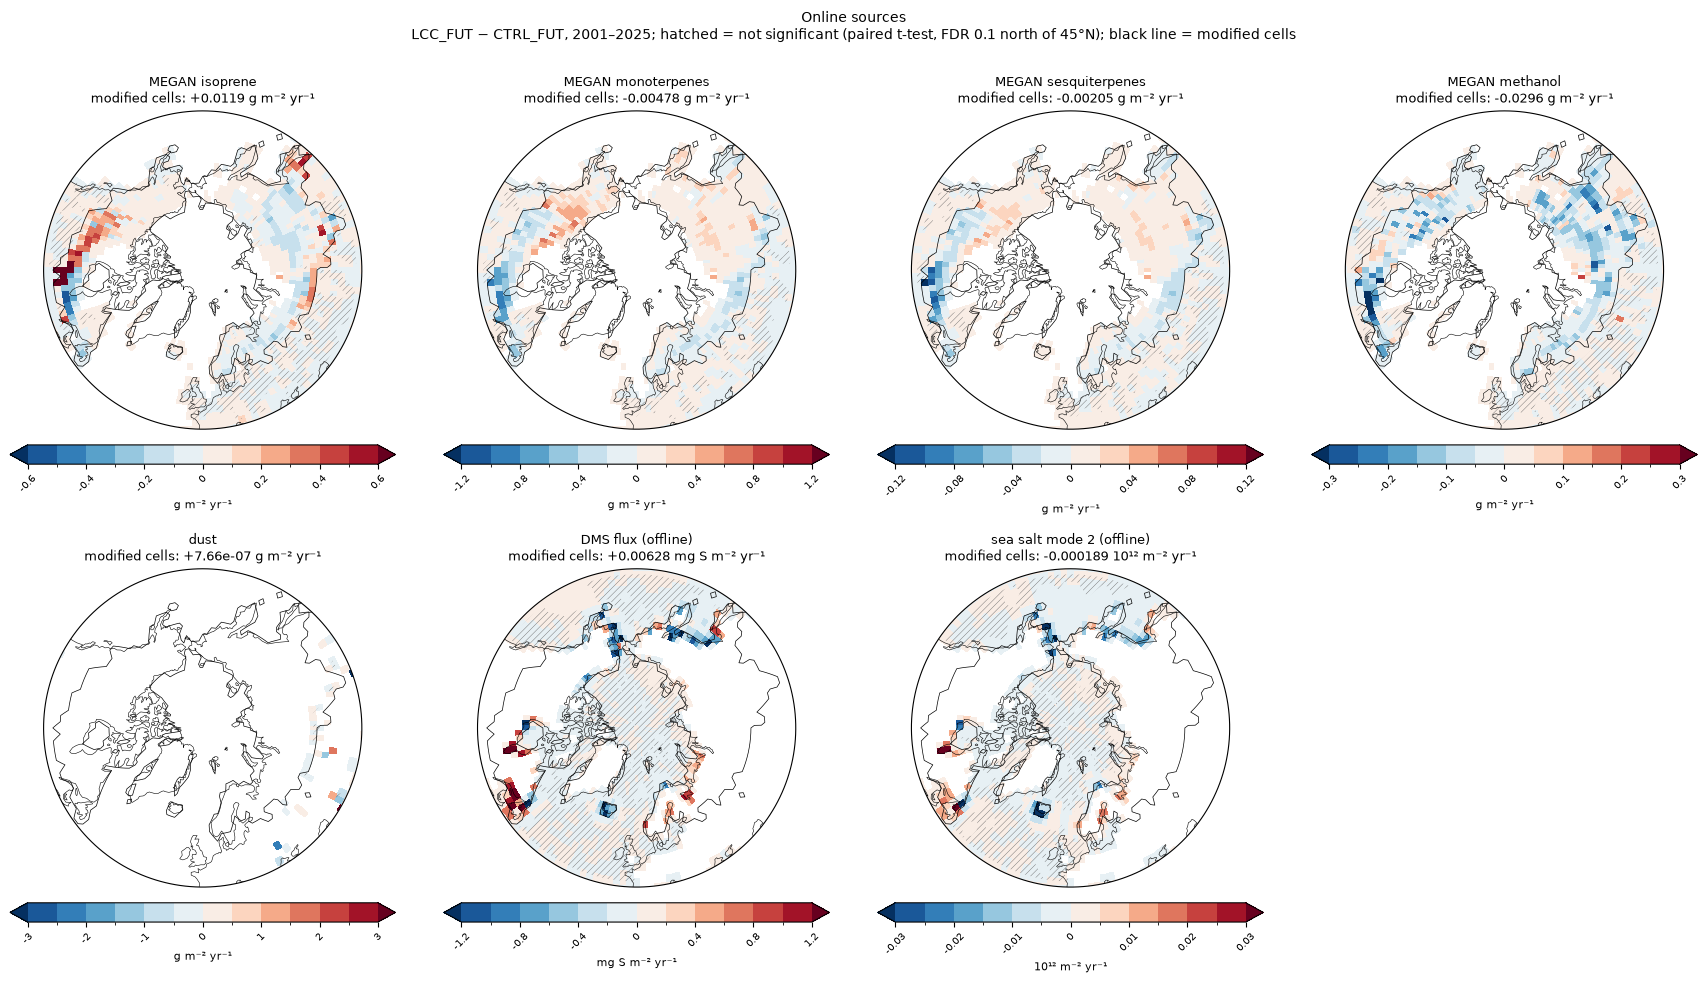

In [5]:
fig, ax = plt.subplots(figsize=(7, 3))
for k in CASES:
    ax.plot(LIGHT[k].index, LIGHT[k].values, 'o-', color=PCOL[k], ms=3, label=f'{ALIAS[k]} (mean {LIGHT[k].mean():.3f})')
ax.set_ylabel('Tg N yr⁻¹'); ax.set_title('Global lightning NOx (atm.log, every time step)')
ax.legend(frameon=False); ax.spines[['top', 'right']].set_visible(False)
fig.savefig(FIG / 'lightning_nox_yearly.png', dpi=200, bbox_inches='tight'); plt.show()

land = (SRC['CTRL'].ISOP.mean('year') > 0) | (SRC['LCC'].ISOP.mean('year') > 0)
dusty = (SRC['CTRL'].dust.mean('year') > 0) | (SRC['LCC'].dust.mean('year') > 0)
ocean = SRC['CTRL'].open_ocean.mean('year') > 0
g = 1e3 * SEC_YR  # kg m-2 s-1 -> g m-2 yr-1
diff_maps([
    ('MEGAN isoprene', 'g m⁻² yr⁻¹', SRC['CTRL'].ISOP * g, SRC['LCC'].ISOP * g, land),
    ('MEGAN monoterpenes', 'g m⁻² yr⁻¹', SRC['CTRL'].MTERP * g, SRC['LCC'].MTERP * g, land),
    ('MEGAN sesquiterpenes', 'g m⁻² yr⁻¹', SRC['CTRL'].BCARY * g, SRC['LCC'].BCARY * g, land),
    ('MEGAN methanol', 'g m⁻² yr⁻¹', SRC['CTRL'].CH3OH * g, SRC['LCC'].CH3OH * g, land),
    ('dust', 'g m⁻² yr⁻¹', SRC['CTRL'].dust * g, SRC['LCC'].dust * g, dusty),
    ('DMS flux (offline)', 'mg S m⁻² yr⁻¹', SRC['CTRL'].DMS_flux * g * 1e3 * MW_S / MW_DMS, SRC['LCC'].DMS_flux * g * 1e3 * MW_S / MW_DMS, ocean),
    ('sea salt mode 2 (offline)', '10¹² m⁻² yr⁻¹', SRC['CTRL'].seasalt_n2 * SEC_YR * 1e-12, SRC['LCC'].seasalt_n2 * SEC_YR * 1e-12, ocean),
], 'online_sources_lcc_minus_ctrl_fut.png', 'Online sources')

## 3. What the model makes of it

Same quantities as the PD/FUT notebook (§6 there), plus the SOA burden, surface isoprene/monoterpenes and OH, which the BVOC change acts on directly. Processed monthly files, yearly means weighted by days per month; surface = lowest model level. SOA burden = `cb_SOA_A1 + cb_SOA_NA + cb_SOA_A1_OCW + cb_SOA_NA_OCW` (model burdens, interstitial + cloud-borne; new-chain fields, present in both runs).

In [6]:
MODEL_VARS = {  # name: (category, variable(s), surface?, factor, unit)
    'AOD 550 nm': ('AEROPT', ['DOD550'], False, 1, '1'),
    'absorption AOD 550 nm': ('AEROPT', ['ABS550'], False, 1, '1'),
    'SOA burden': ('SOA', ['cb_SOA_A1', 'cb_SOA_NA', 'cb_SOA_A1_OCW', 'cb_SOA_NA_OCW'], False, 1e6, 'mg m⁻²'),
    'sulfate burden': ('SULFATE', ['cb_SULFATE'], False, 1e6, 'mg m⁻²'),
    'droplet column': ('CLOUDPROP', ['CDNUMC'], False, 1e-10, '10¹⁰ m⁻²'),
    'surface isoprene': ('BVOC', ['ISOP'], True, 1e12, 'ppt'),
    'surface monoterpenes': ('BVOC', ['MTERP'], True, 1e12, 'ppt'),
    'surface OH': ('CHEM', ['OH'], True, 1e15, 'ppq'),
    'surface SO₂': ('SULFATE', ['SO2'], True, 1e12, 'ppt'),
    'surface DMS': ('SULFATE', ['DMS'], True, 1e12, 'ppt'),
    'surface NOx': ('CHEM', ['NO', 'NO2'], True, 1e12, 'ppt'),
    'surface O₃': ('CHEM', ['O3'], True, 1e9, 'ppb'),
    'surface CO': ('CHEM', ['CO'], True, 1e9, 'ppb'),
    'surface CH₄': ('CHEM', ['CH4'], True, 1e9, 'ppb'),
    'O₃ column': ('CHEM', ['cb_O3'], False, 1e3, 'g m⁻²'),
}

def load_model(k):
    out, files = {}, {}
    for name, (cat, vs, sfc, fac, unit) in MODEL_VARS.items():
        f = PROC / f'{ALIAS[k]}_atm_{cat}_{PROC_YEARS}.nc'
        if f not in files:
            files[f] = xr.open_dataset(f)
            assert files[f].attrs['casename'] == CASES[k], (f, files[f].attrs['casename'])
            assert files[f].time.encoding.get('calendar') == 'noleap'
        ds = files[f]
        if sfc:
            assert float(ds.lev[-1]) > 900
        da = sum(ds[v].isel(lev=-1) if sfc else ds[v] for v in vs)
        out[name] = (yearly(da, YEARS) * fac).assign_coords(lat=AREA.lat, lon=AREA.lon).load()
    for ds in files.values():
        ds.close()
    return out

MODEL = {k: load_model(k) for k in CASES}
MODEL_TAB = region_table({n: (MODEL_VARS[n][4], MODEL['CTRL'][n], MODEL['LCC'][n], 1, 'mean') for n in MODEL_VARS},
                         f'model_levels_lcc_ctrl_fut_{YEARS[0]}-{YEARS[-1]}.csv')
show(MODEL_TAB)

global


,,CTRL_FUT,LCC_FUT,LCC − CTRL,change %,95 % CI ±,p
variable,unit,,,,,,
AOD 550 nm,1,0.216,0.216,-3.4e-05,-0.0158,0.000623,0.911
absorption AOD 550 nm,1,0.0044,0.0044,4.95e-07,0.0113,1.56e-05,0.948
SOA burden,mg m⁻²,6.71,6.72,0.00253,0.0377,0.0114,0.651
sulfate burden,mg m⁻²,3.78,3.79,0.00477,0.126,0.00302,0.00331
droplet column,10¹⁰ m⁻²,1.05,1.05,-0.000651,-0.0621,0.000721,0.0746
surface isoprene,ppt,1.67e+03,1.68e+03,3.72,0.222,4.01,0.0677
surface monoterpenes,ppt,532,533,0.922,0.173,1.07,0.0874
surface OH,ppq,48.3,48.3,0.00551,0.0114,0.0186,0.548
surface SO₂,ppt,96.9,96.9,0.022,0.0227,0.0431,0.303


modified cells


,,CTRL_FUT,LCC_FUT,LCC − CTRL,change %,95 % CI ±,p
variable,unit,,,,,,
AOD 550 nm,1,0.0876,0.0875,-0.000101,-0.115,0.000371,0.581
absorption AOD 550 nm,1,0.00239,0.00239,8.83e-07,0.0369,8.29e-06,0.828
SOA burden,mg m⁻²,4.07,4.08,0.00921,0.226,0.0107,0.0884
sulfate burden,mg m⁻²,4.74,4.74,0.00423,0.0893,0.0072,0.237
droplet column,10¹⁰ m⁻²,1.54,1.53,-0.0115,-0.746,0.00141,9.1e-15
surface isoprene,ppt,235,240,5.01,2.13,1.05,7.34e-10
surface monoterpenes,ppt,194,192,-2.82,-1.45,0.59,6.64e-10
surface OH,ppq,15.7,15.8,0.0762,0.486,0.0113,5.08e-13
surface SO₂,ppt,73.7,74.3,0.573,0.777,0.122,8.92e-10


46–82°N


,,CTRL_FUT,LCC_FUT,LCC − CTRL,change %,95 % CI ±,p
variable,unit,,,,,,
AOD 550 nm,1,0.114,0.113,-0.000244,-0.215,0.000441,0.265
absorption AOD 550 nm,1,0.00258,0.00258,-2.26e-06,-0.0876,9.66e-06,0.633
SOA burden,mg m⁻²,3.95,3.95,-0.000688,-0.0174,0.0108,0.896
sulfate burden,mg m⁻²,4.79,4.79,0.00499,0.104,0.00703,0.156
droplet column,10¹⁰ m⁻²,1.58,1.58,-0.00583,-0.368,0.000912,1.7e-12
surface isoprene,ppt,151,154,2.45,1.62,0.482,1.97e-10
surface monoterpenes,ppt,113,112,-1.21,-1.07,0.279,4e-09
surface OH,ppq,23.4,23.4,0.0477,0.204,0.0111,4.64e-09
surface SO₂,ppt,82.2,82.5,0.267,0.325,0.055,4.54e-10


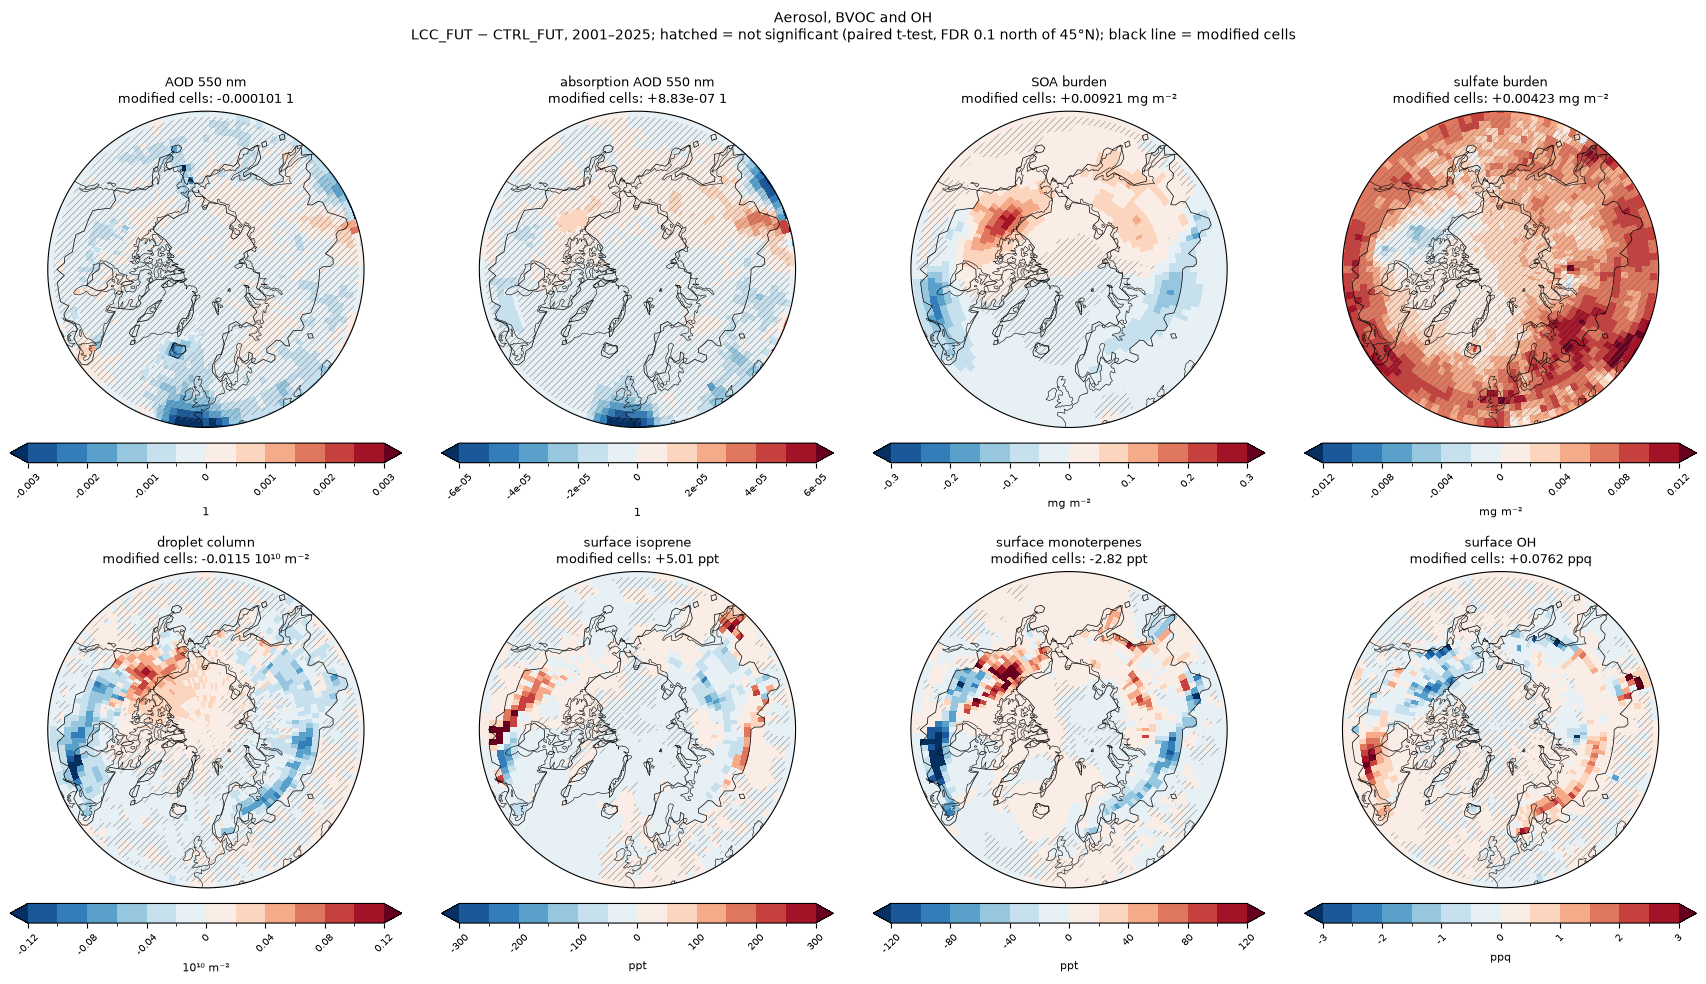

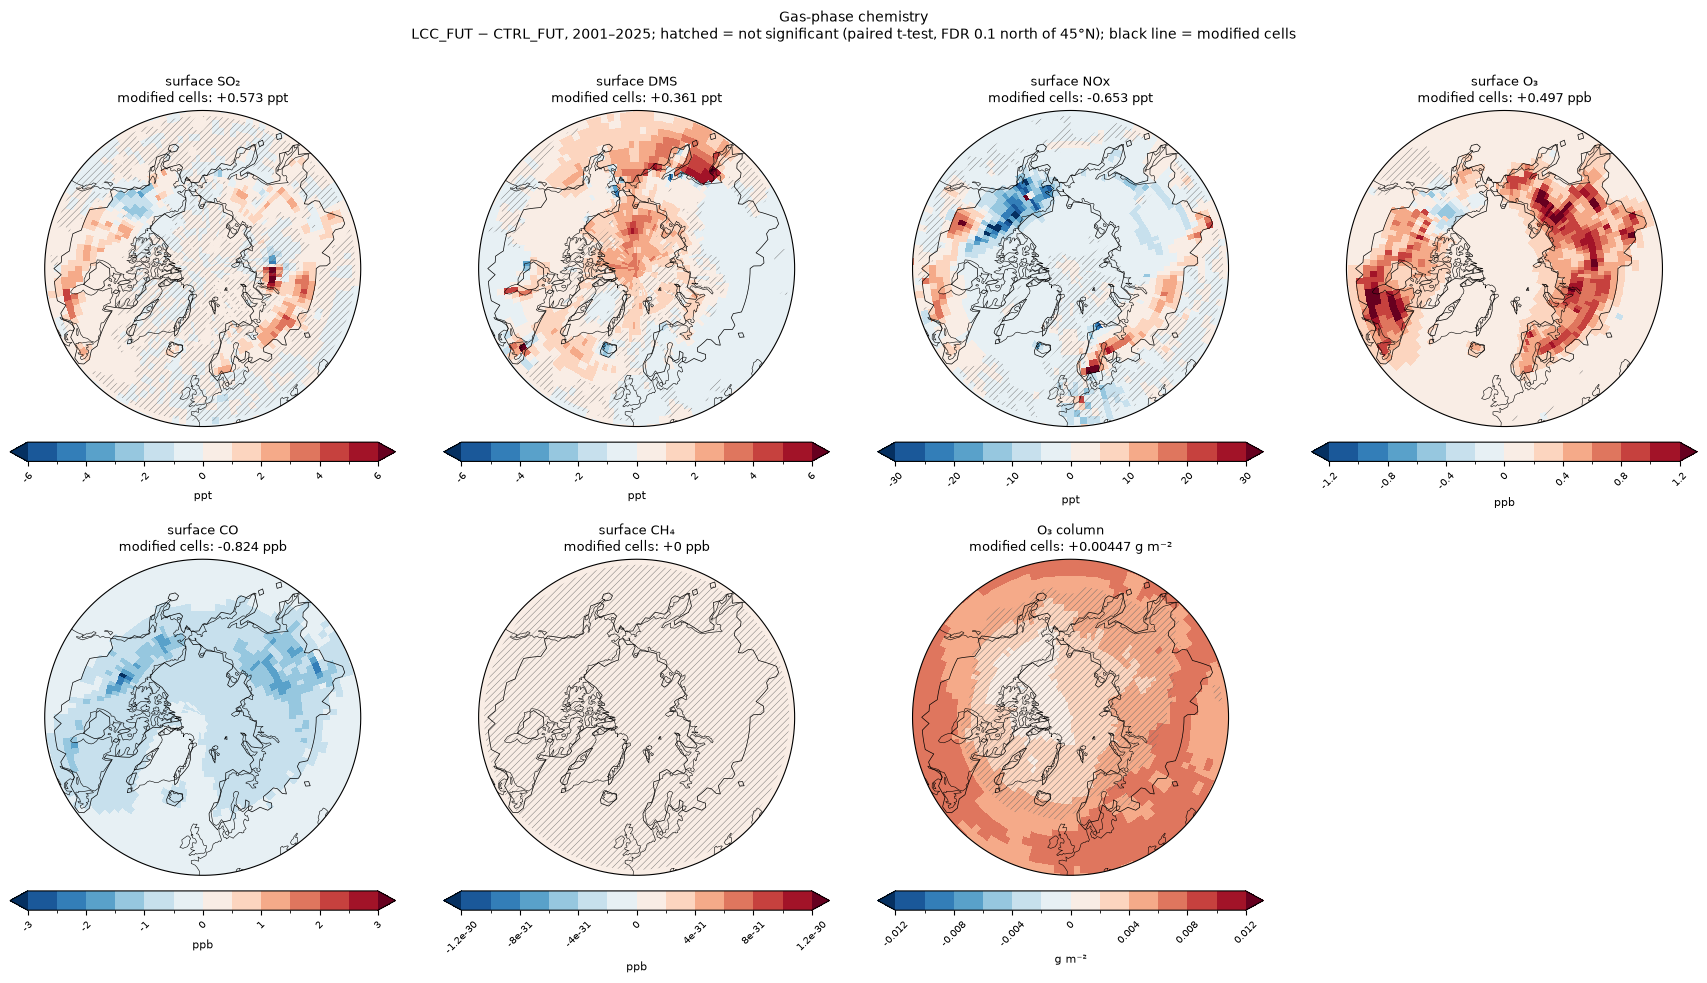

In [7]:
allc = AREA > 0
diff_maps([(n, MODEL_VARS[n][4], MODEL['CTRL'][n], MODEL['LCC'][n], allc) for n in
           ['AOD 550 nm', 'absorption AOD 550 nm', 'SOA burden', 'sulfate burden', 'droplet column', 'surface isoprene',
            'surface monoterpenes', 'surface OH']], 'model_lcc_minus_ctrl_fut_aerosol_bvoc.png', 'Aerosol, BVOC and OH')
diff_maps([(n, MODEL_VARS[n][4], MODEL['CTRL'][n], MODEL['LCC'][n], allc) for n in
           ['surface SO₂', 'surface DMS', 'surface NOx', 'surface O₃', 'surface CO', 'surface CH₄', 'O₃ column']],
          'model_lcc_minus_ctrl_fut_chemistry.png', 'Gas-phase chemistry')

## 4. Summary

LCC_FUT − CTRL_FUT, 2001–2025, paired yearly differences. Tags: **(a)** read from the tables above · **(b)** inference.

**Inputs (a).** The resolved namelists are identical except: initial files (`ncdata`, `finidat`, `ice_ic`, `finidat_rtm`: each run starts from its own spin-up), `fsurdat` (the land cover), and CTRL_FUT's extra 30-min BVOC output tape (`fincl2`, output only). Same emission files, seawater DMS, SST/sea ice and greenhouse gases. So **every difference comes from the land**.

**Online sources** (a)

| | modified cells | 46–82°N | global |
|---|---|---|---|
| MEGAN isoprene | **+2.8 %** (+0.35 Tg yr⁻¹) | +1.6 % | +0.15 % |
| MEGAN monoterpenes | **−0.6 %** | −0.3 % | +0.08 % (n.s.) |
| MEGAN sesquiterpenes | **−2.9 %** | −1.7 % | n.s. |
| MEGAN methanol | **−4.8 %** | −2.5 % | −0.25 % |
| MEGAN other 15 species | **−5.1 %** | −2.7 % | −0.12 % |
| dust | n.s. | n.s. | n.s. |
| DMS flux, sea salt (offline) | < 0.6 % (wind only) | < 0.1 % | n.s. |
| lightning NOx | – | – | +0.15 % (n.s., p = 0.29) |

**What the model makes of it** (a), modified cells: surface isoprene +2.1 %, monoterpenes −1.5 %, OH +0.5 %, **O₃ +1.3 % (+0.5 ppb)**, CO −0.8 %, SO₂ +0.8 %, DMS +0.5 %, **droplet column −0.75 %** (all p < 10⁻⁸). SOA burden +0.2 % (p = 0.09), sulfate burden, AOD and absorption AOD not significant. Globally every change is ≤ 0.2 %.

Inferences (b):
- The forest expansion **does not change the FUT aerosol background** in a meaningful way: the sources that matter for aerosol (sulfur, fires, dust, sea salt) are unchanged, and the BVOC change is a **shift in composition** (more isoprene, fewer monoterpenes, sesquiterpenes and oxygenated VOCs) rather than more BVOC, so SOA barely moves.
- Monoterpenes, the main SOA precursor in this mechanism (yield 0.15 vs 0.025 for isoprene), go **down** although the forest expands. Why (PFT mix of the LPJ-GUESS land cover, emission factors, leaf temperature) is not checked here; the MEGAN LMDI split addresses it.
- The droplet-column decrease, with AOD/SOA/sulfate unchanged, points to the **meteorology** (cloud amount, boundary layer over a darker, rougher surface) rather than to aerosol. Not checked here.
- The O₃ increase and CO/NOx decrease fit more isoprene oxidation and a warmer, more reactive boundary layer. Not separated here.
